# Customer churn: who leaves, why, and whom to contact

**Question.** A telecom company loses about a quarter of its customers. Which customers are likely to leave,
what drives it, and how should a limited retention budget be spent?

**Data.** IBM Telco Customer Churn sample dataset: 7,043 customers, 19 features (demographics, services,
contract, billing) and a yes/no `Churn` label.

**Plan.**
1. Clean the data and explore it with **SQL** (SQLite).
2. Compare a linear model with two tree ensembles using **stratified 5-fold cross-validation**.
3. Diagnose **overfitting vs underfitting** with a validation curve.
4. Evaluate the chosen model once on a held-out **test set** and interpret it.
5. Choose a decision threshold from a simple **profit model** instead of the default 0.5.
6. Find behaviour-based customer **segments with k-means** (unsupervised) and compare their churn.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

from churn.data import load_raw, clean, split_xy
from churn.db import build_database, load_named_queries, run_query
from churn.models import candidate_models, compare_models, depth_curve, logistic_coefficients, top_decile_lift
from churn.business import CampaignAssumptions, profit_curve, best_threshold
from churn.segment import silhouette_by_k, fit_segments, describe_segments

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

## 1. Load and clean

In [2]:
raw = load_raw(ROOT / "data" / "Telco-Customer-Churn.csv")
print(raw.shape)
blank = raw["TotalCharges"].str.strip() == ""
print("Blank TotalCharges:", blank.sum(), "| their tenure values:", raw.loc[blank, "tenure"].unique())

(7043, 21)
Blank TotalCharges: 11 | their tenure values: [0]


`TotalCharges` is stored as text, and the 11 blank values all belong to customers with `tenure = 0`:
they have not been billed yet, so the correct value is 0 rather than a mean or median imputation.
`clean()` checks this assumption and raises an error if it ever stops being true.

In [3]:
df = clean(raw)
print(df.dtypes.value_counts())
print(f"Churn rate: {df['Churn'].mean():.1%}")

str        12
int64       7
float64     2
Name: count, dtype: int64
Churn rate: 26.5%


The classes are imbalanced (≈27% churn), so accuracy alone would be misleading. I use ROC-AUC, PR-AUC and F1.

## 2. Exploratory analysis in SQL

The cleaned table is loaded into an SQLite database; the queries live in `sql/eda_queries.sql`.

In [4]:
conn = build_database(df)
Q = load_named_queries(ROOT / "sql" / "eda_queries.sql")
for name in ["churn_by_contract", "churn_by_tenure_band", "churn_by_payment_method",
             "fiber_without_support", "monthly_revenue_at_risk"]:
    print(f"--- {name}")
    print(run_query(conn, Q[name]).to_string(index=False), end="\n\n")

--- churn_by_contract
      Contract  customers  churn_rate_pct  avg_monthly_charges
Month-to-month       3875            42.7                66.40
      One year       1473            11.3                65.05
      Two year       1695             2.8                60.77

--- churn_by_tenure_band
 tenure_band  customers  churn_rate_pct
 0-11 months       2069            48.3
12-23 months       1047            29.5
24-47 months       1624            20.9
  48+ months       2303             9.6

--- churn_by_payment_method
            PaymentMethod  customers  churn_rate_pct
         Electronic check       2365            45.3
             Mailed check       1612            19.1
Bank transfer (automatic)       1544            16.7
  Credit card (automatic)       1522            15.2

--- fiber_without_support
TechSupport  customers  churn_rate_pct
         No       2230            49.4
        Yes        866            22.6

--- monthly_revenue_at_risk
      Contract  lost_monthly_reve

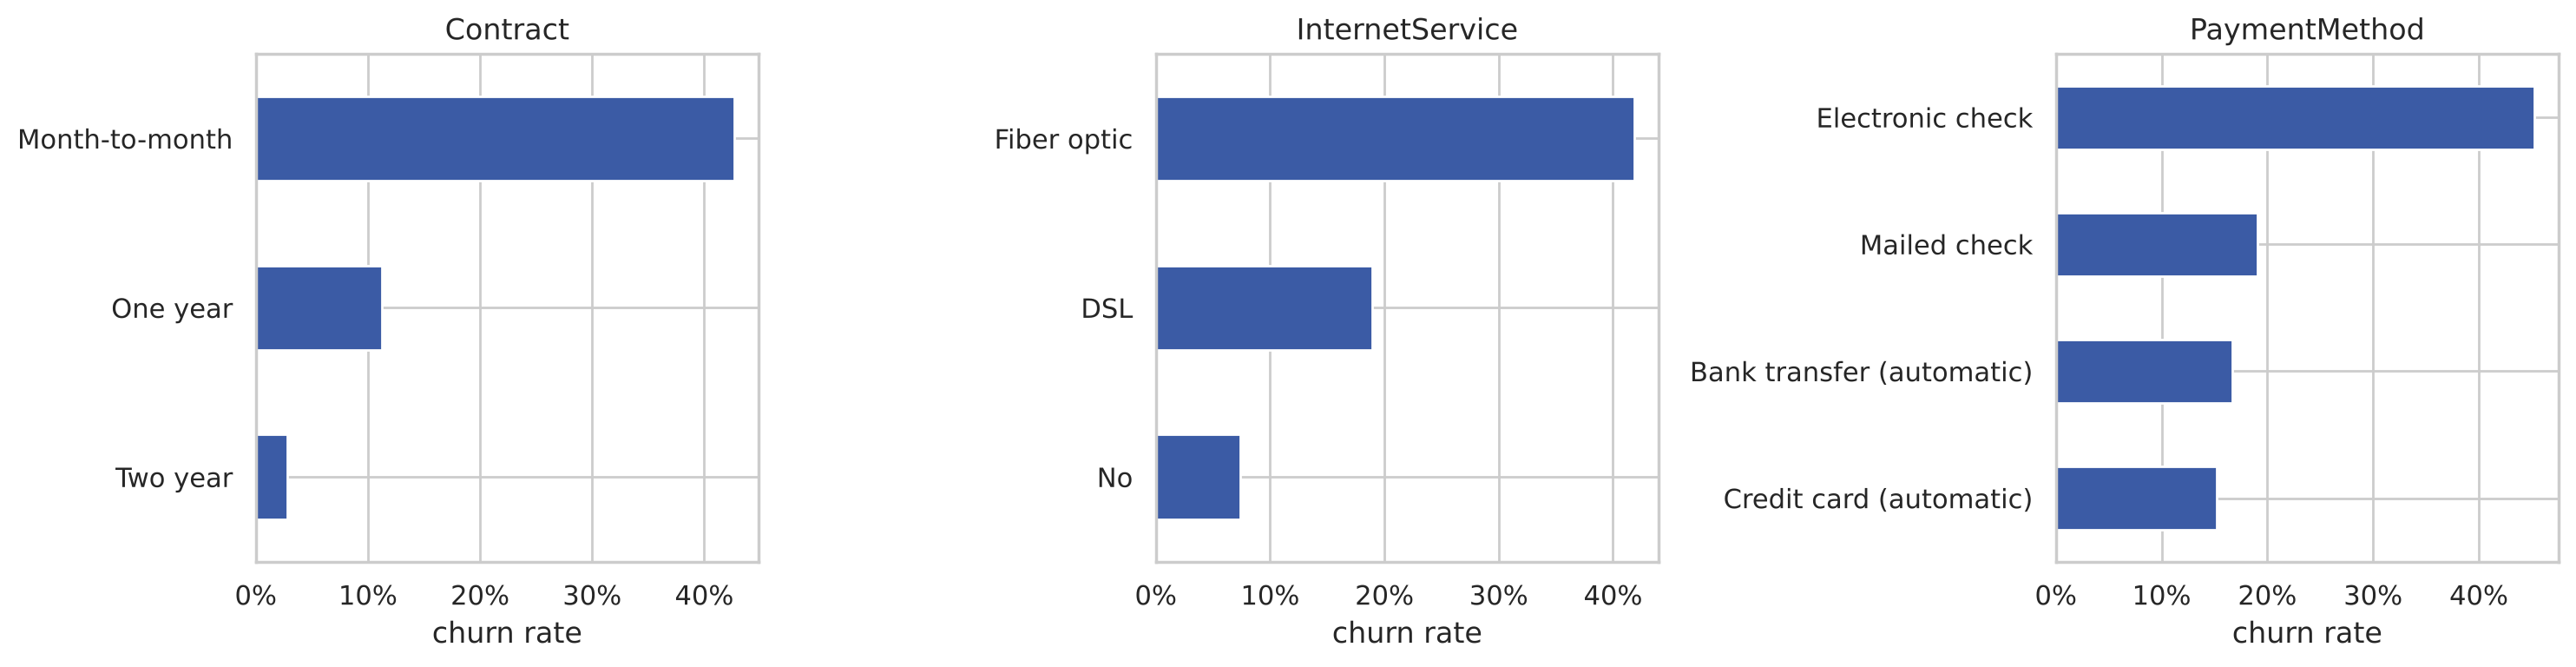

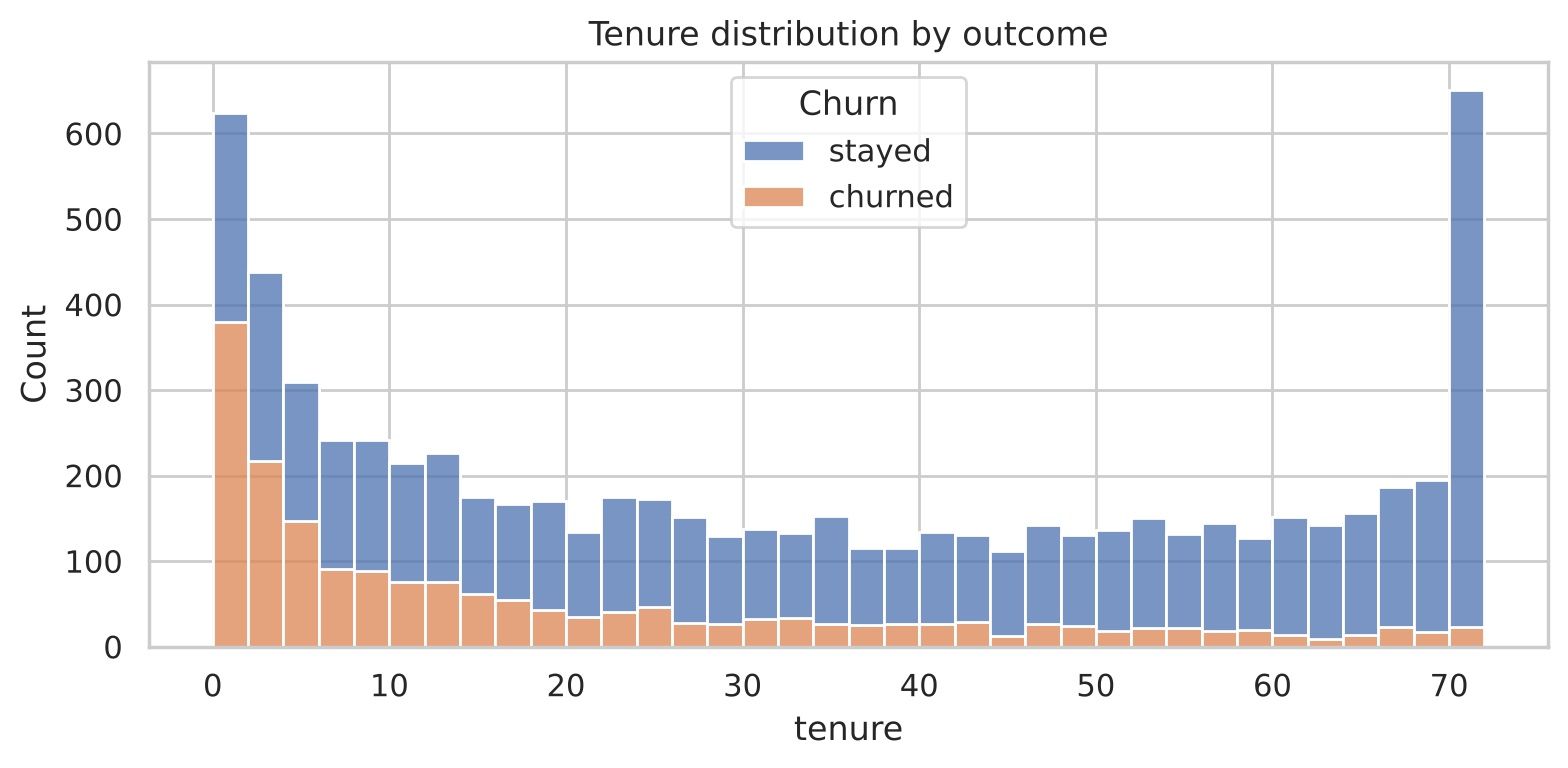

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].mean().sort_values()
    rate.plot.barh(ax=ax, color="#3b5ba5")
    ax.set_xlabel("churn rate"); ax.set_ylabel(""); ax.set_title(col)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(FIG / "churn_by_category.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="tenure", hue=df["Churn"].map({0: "stayed", 1: "churned"}),
             bins=36, multiple="stack", ax=ax)
ax.set_title("Tenure distribution by outcome")
plt.tight_layout(); plt.savefig(FIG / "tenure_by_churn.png", dpi=150); plt.show()

**Findings.**
* Month-to-month contracts churn at ~43% vs ~3% for two-year contracts, and they account for most lost revenue.
* Churn is concentrated in the first year of tenure (~48%) and falls steadily after that.
* Electronic-check payers churn about 3× as often as customers on automatic payment.
* Among fiber-optic customers, those without tech support churn at roughly twice the rate of those with it.

These are correlations, not causes: for example, customers who commit to a two-year contract were probably
less likely to leave in the first place.

## 3. Train/test split and model comparison

20% of the data is held out as a test set and is not touched until the final evaluation.
On the remaining 80%, three models are compared with stratified 5-fold cross-validation.
All preprocessing (feature engineering, scaling, one-hot encoding) is inside each pipeline, so it is
re-fitted on every training fold and never sees the validation fold (no leakage).

Two engineered features are added: `num_addon_services` (0–6 optional services) and
`avg_monthly_spend` (`TotalCharges / tenure`).

In [6]:
X, y = split_xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "test:", X_test.shape)

comparison = compare_models(X_train, y_train)
cols = ["val_roc_auc", "val_roc_auc_std", "train_roc_auc", "val_pr_auc", "val_f1", "train_f1"]
comparison[cols].round(3)

train: (5634, 19) test: (1409, 19)


,val_roc_auc,val_roc_auc_std,train_roc_auc,val_pr_auc,val_f1,train_f1
model,,,,,,
Logistic regression,0.846,0.013,0.850,0.660,0.593,0.603
Gradient boosting,0.845,0.010,0.893,0.662,0.583,0.644
Random forest,0.845,0.010,0.941,0.658,0.569,0.725


All three models reach about the same validation ROC-AUC (≈0.845, differences smaller than one standard
deviation across folds). The tree ensembles fit the training folds noticeably better than the validation
folds (random forest train F1 ≈ 0.73 vs validation ≈ 0.57), while logistic regression has almost no gap.

**Choice: logistic regression.** It is as accurate as the more complex models, generalises with the smallest
train/validation gap, is fast, and its coefficients can be explained to a business audience.

## 4. Overfitting vs underfitting: random forest depth

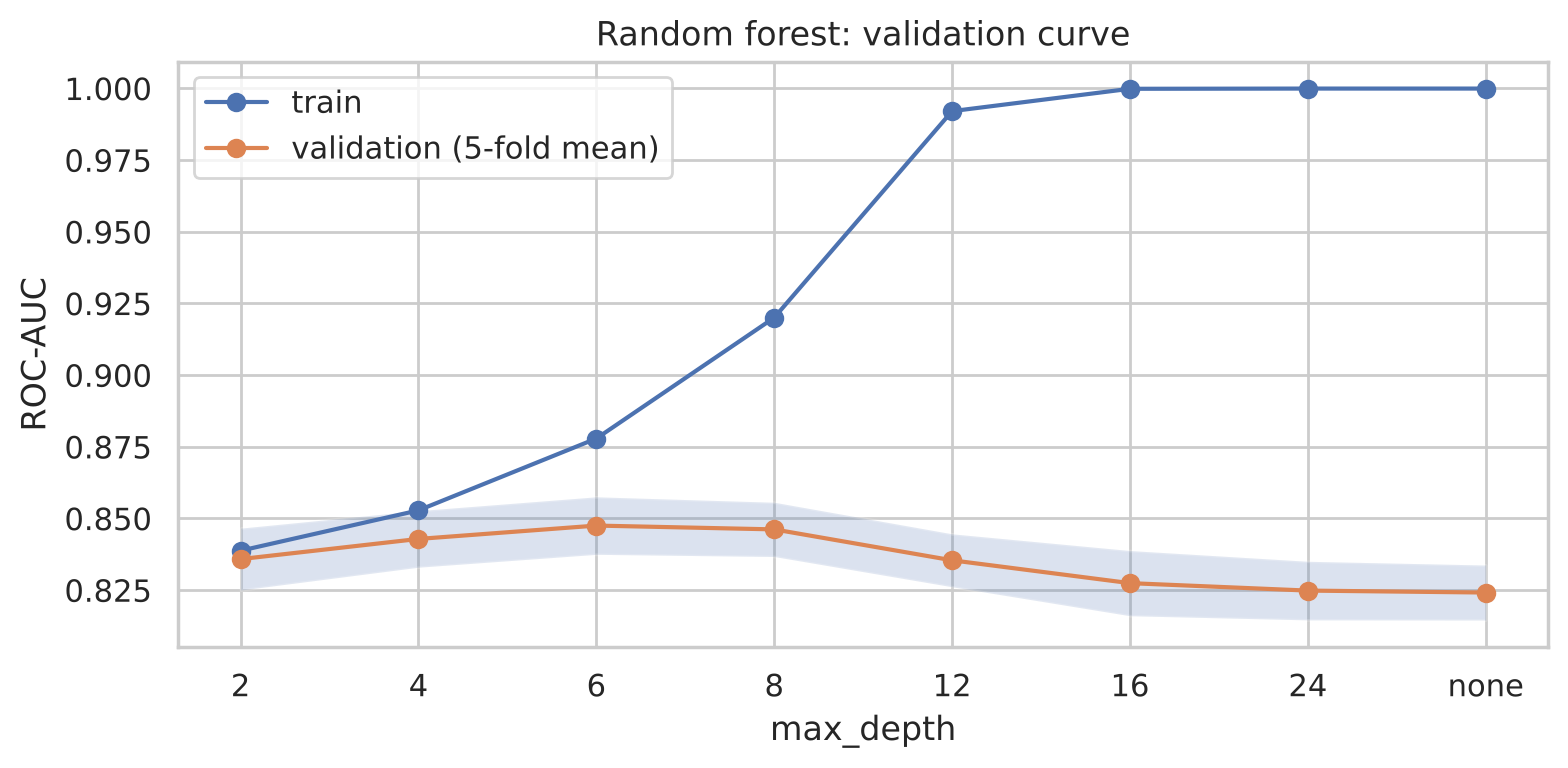

,max_depth,train_roc_auc,val_roc_auc,val_std
0,2,0.839,0.836,0.011
1,4,0.853,0.843,0.010
2,6,0.878,0.848,0.010
3,8,0.920,0.846,0.009
4,12,0.992,0.835,0.009
5,16,1.000,0.827,0.011
6,24,1.000,0.825,0.010
7,none,1.000,0.824,0.010


In [7]:
curve = depth_curve(X_train, y_train)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(curve))
ax.plot(x, curve["train_roc_auc"], marker="o", label="train")
ax.plot(x, curve["val_roc_auc"], marker="o", label="validation (5-fold mean)")
ax.fill_between(x, curve["val_roc_auc"] - curve["val_std"], curve["val_roc_auc"] + curve["val_std"], alpha=0.2)
ax.set_xticks(x, curve["max_depth"]); ax.set_xlabel("max_depth"); ax.set_ylabel("ROC-AUC")
ax.set_title("Random forest: validation curve"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "depth_validation_curve.png", dpi=150); plt.show()
curve.round(3)

* **Depth 2 – underfitting:** train and validation scores are both low and close together.
* **Depth ≈ 6 – best:** validation ROC-AUC peaks.
* **Depth ≥ 12 – overfitting:** the training score goes to 1.0 (the trees memorise the training data)
  while the validation score falls.

## 5. Final evaluation on the held-out test set

In [8]:
model = candidate_models()["Logistic regression"].fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, proba):.3f}  (a random model would score {y_test.mean():.3f})")
print(f"Top-decile lift: {top_decile_lift(y_test, proba):.2f}x")
print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=["stayed", "churned"]))

Test ROC-AUC: 0.842
Test PR-AUC:  0.634  (a random model would score 0.265)
Top-decile lift: 2.83x
              precision    recall  f1-score   support

      stayed       0.85      0.90      0.87      1035
     churned       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



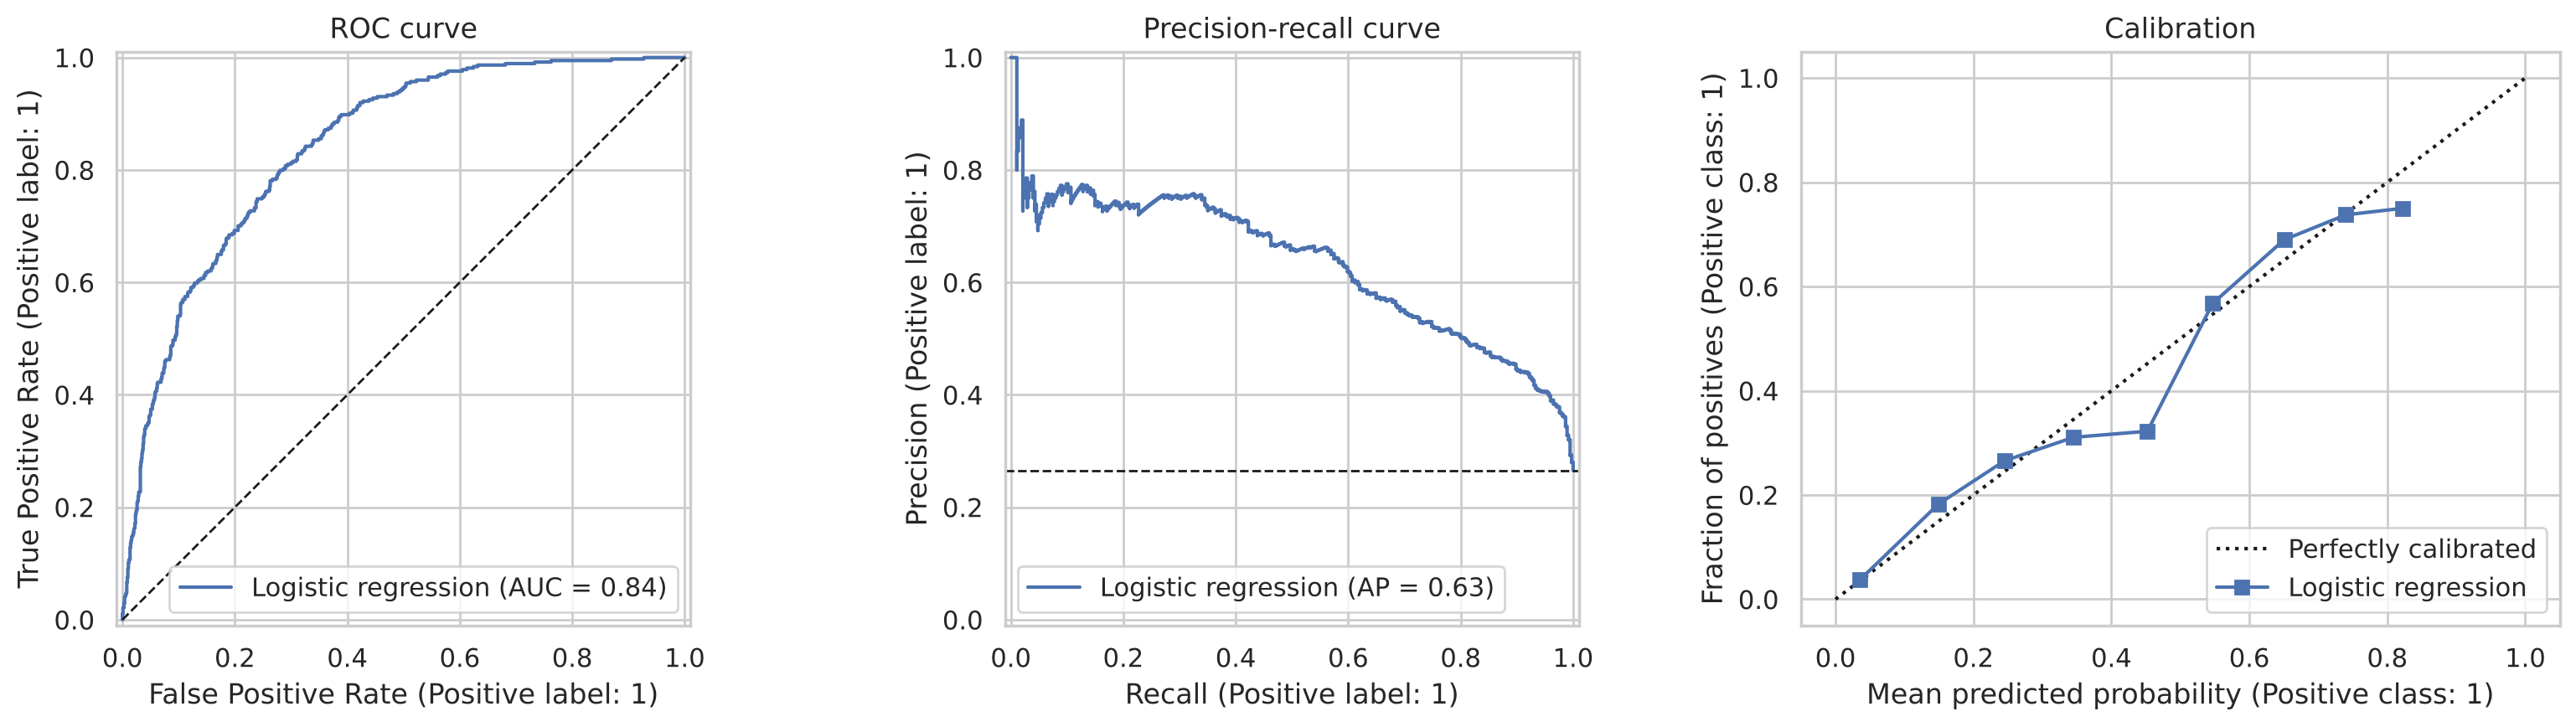

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name="Logistic regression")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[1], name="Logistic regression")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1); axes[1].set_title("Precision-recall curve")
CalibrationDisplay.from_predictions(y_test, proba, n_bins=10, ax=axes[2], name="Logistic regression")
axes[2].set_title("Calibration")
plt.tight_layout(); plt.savefig(FIG / "test_evaluation.png", dpi=150); plt.show()

The test scores match the cross-validation estimates, so the CV results were not over-optimistic.
The calibration curve stays close to the diagonal, meaning a predicted probability of 0.3 really corresponds
to roughly a 30% churn rate. That matters for the profit calculation below.

## 6. What drives the predictions?

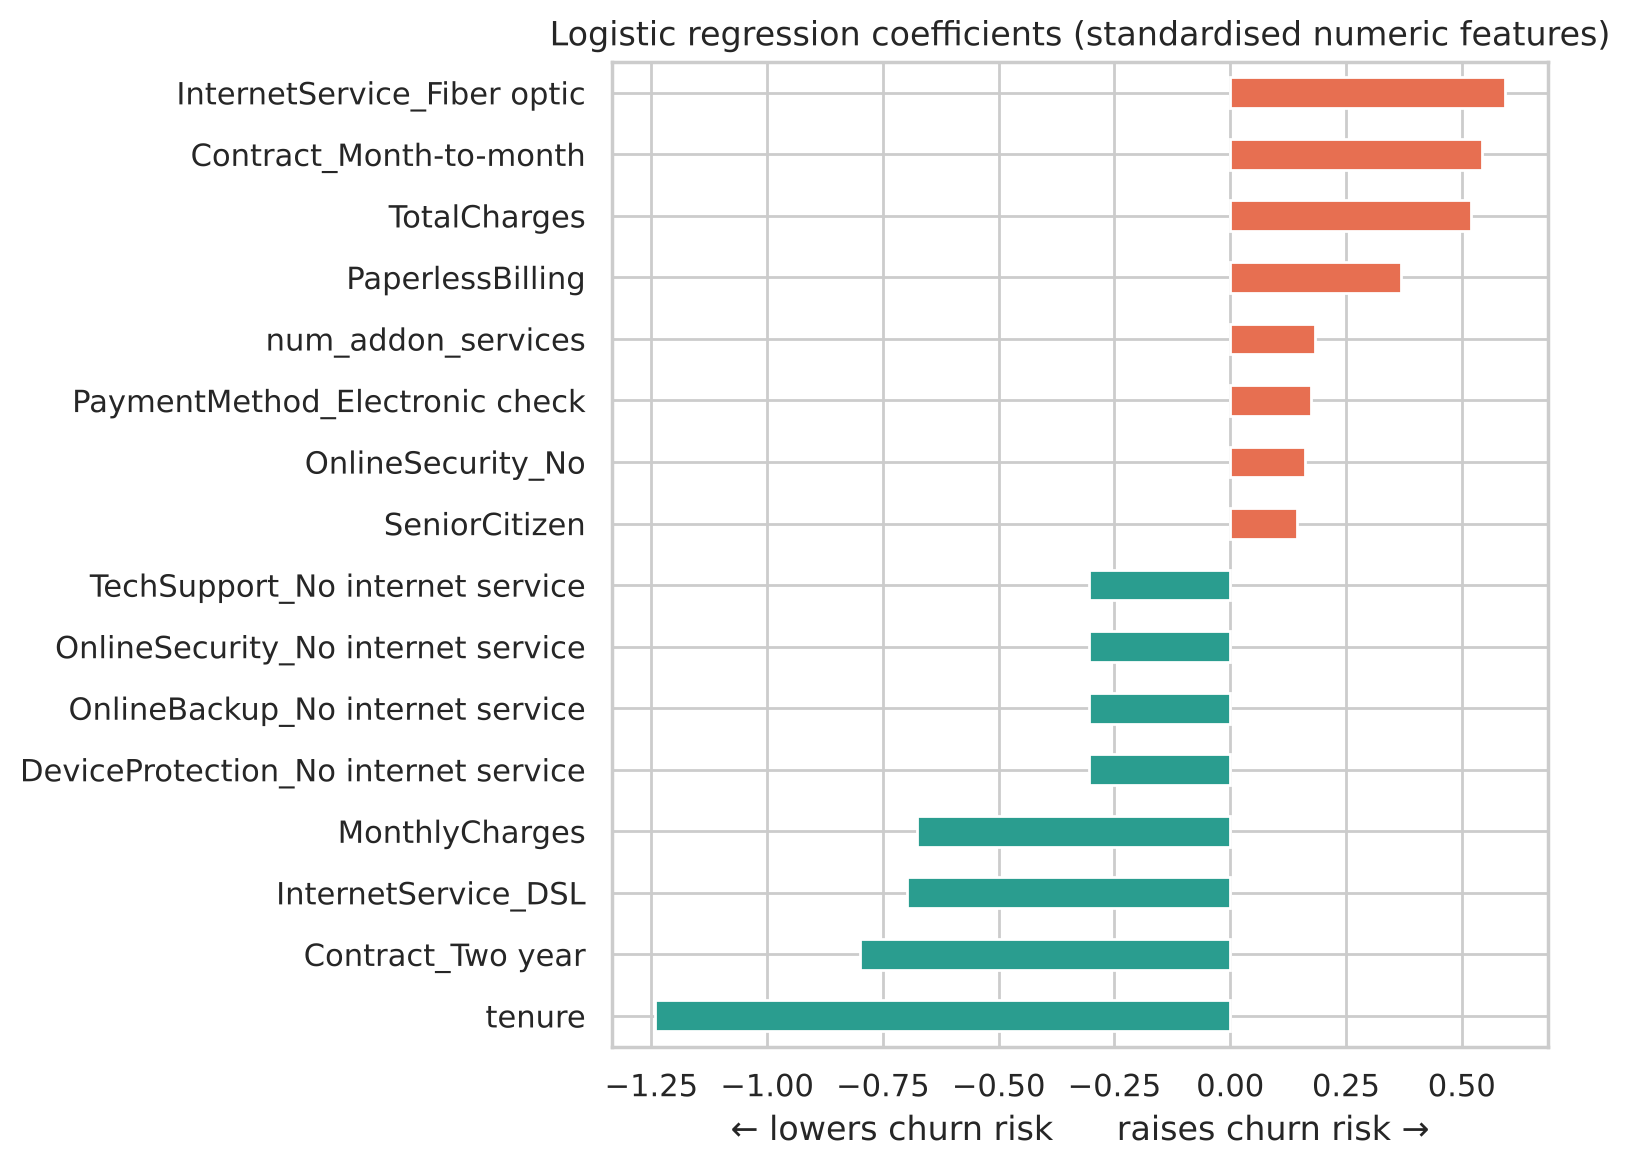

In [10]:
coefs = logistic_coefficients(model)
top = pd.concat([coefs.head(8), coefs.tail(8)])
fig, ax = plt.subplots(figsize=(8, 6))
top.plot.barh(ax=ax, color=["#2a9d8f" if v < 0 else "#e76f51" for v in top])
ax.set_title("Logistic regression coefficients (standardised numeric features)")
ax.set_xlabel("← lowers churn risk      raises churn risk →")
plt.tight_layout(); plt.savefig(FIG / "lr_coefficients.png", dpi=150); plt.show()

In [11]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(10).round(4).to_frame("ROC-AUC drop when shuffled")

,ROC-AUC drop when shuffled
tenure,0.2297
MonthlyCharges,0.0384
InternetService,0.0375
Contract,0.0338
TotalCharges,0.0329
OnlineSecurity,0.0042
StreamingMovies,0.0037
TechSupport,0.0036
StreamingTV,0.0034
PaymentMethod,0.0031


Short tenure, month-to-month contracts and fiber-optic internet push risk up; long tenure and two-year contracts
push it down. Permutation importance (how much test ROC-AUC drops when one column is shuffled) agrees on the
leading factors.

**Caveat.** `tenure`, `MonthlyCharges` and `TotalCharges` are strongly correlated
(`TotalCharges ≈ tenure × MonthlyCharges`), so individual coefficients of these three should not be read
in isolation; permutation importance is the more reliable view for them.

## 7. From probabilities to a decision: choosing the threshold

Suppose the company can offer a retention deal. Illustrative assumptions (not real company figures):

* the offer costs **$50** per contacted customer,
* **30%** of contacted customers who would have churned stay because of it,
* a saved customer brings **12 more months** of their monthly charges.

The profit of contacting everyone above a threshold `t` is
`0.30 × 12 × (monthly charges of real churners contacted) − 50 × (customers contacted)`.

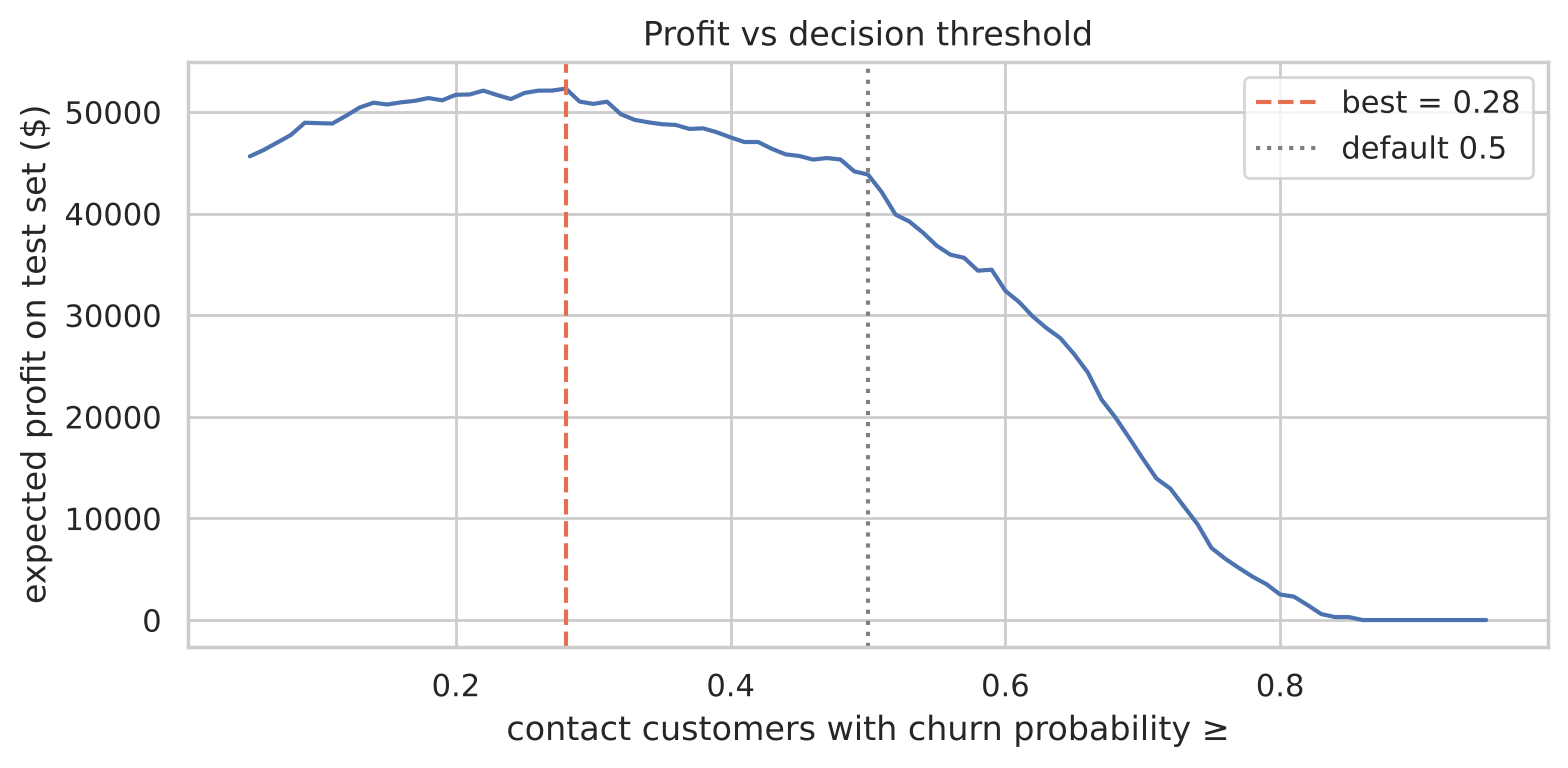

Best threshold 0.28: contact 564 customers, profit $52,311
Default 0.50:      contact 319 customers, profit $43,849


In [12]:
assumptions = CampaignAssumptions(offer_cost=50, success_rate=0.30, months_retained=12)
pc = profit_curve(y_test, proba, X_test["MonthlyCharges"], assumptions)
best = best_threshold(pc)
at_half = pc.loc[pc["threshold"].sub(0.5).abs().idxmin()]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pc["threshold"], pc["profit"])
ax.axvline(best["threshold"], color="#e76f51", ls="--", label=f"best = {best['threshold']:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax.set_xlabel("contact customers with churn probability ≥"); ax.set_ylabel("expected profit on test set ($)")
ax.set_title("Profit vs decision threshold"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "profit_curve.png", dpi=150); plt.show()

print(f"Best threshold {best['threshold']:.2f}: contact {best['customers_contacted']:.0f} customers, "
      f"profit ${best['profit']:,.0f}")
print(f"Default 0.50:      contact {at_half['customers_contacted']:.0f} customers, profit ${at_half['profit']:,.0f}")

In [13]:
rows = []
for cost in [25, 50, 100]:
    for rate in [0.2, 0.3, 0.5]:
        b = best_threshold(profit_curve(y_test, proba, X_test["MonthlyCharges"],
                                        CampaignAssumptions(cost, rate, 12)))
        rows.append({"offer_cost": cost, "success_rate": rate, "best_threshold": b["threshold"],
                     "contacted": int(b["customers_contacted"]), "profit": round(b["profit"])})
pd.DataFrame(rows).pivot(index="offer_cost", columns="success_rate", values="best_threshold")

success_rate,0.2,0.3,0.5
offer_cost,,,
25,0.14,0.09,0.05
50,0.28,0.28,0.09
100,0.59,0.48,0.28


Under these assumptions the profit-maximising threshold is well below 0.5: missing a churner costs more than
an unnecessary offer, so it pays to contact more customers. Cheaper or more effective offers push the
threshold down further; expensive or weak offers push it up. The point is not the exact dollar figure but
that the threshold should come from the business trade-off, not from the default.

## 8. Unsupervised: customer segments

k-means is run on three behavioural features (`tenure`, `MonthlyCharges`, `num_addon_services`), standardised.
The churn label is **not** used to form clusters, only to describe them afterwards.

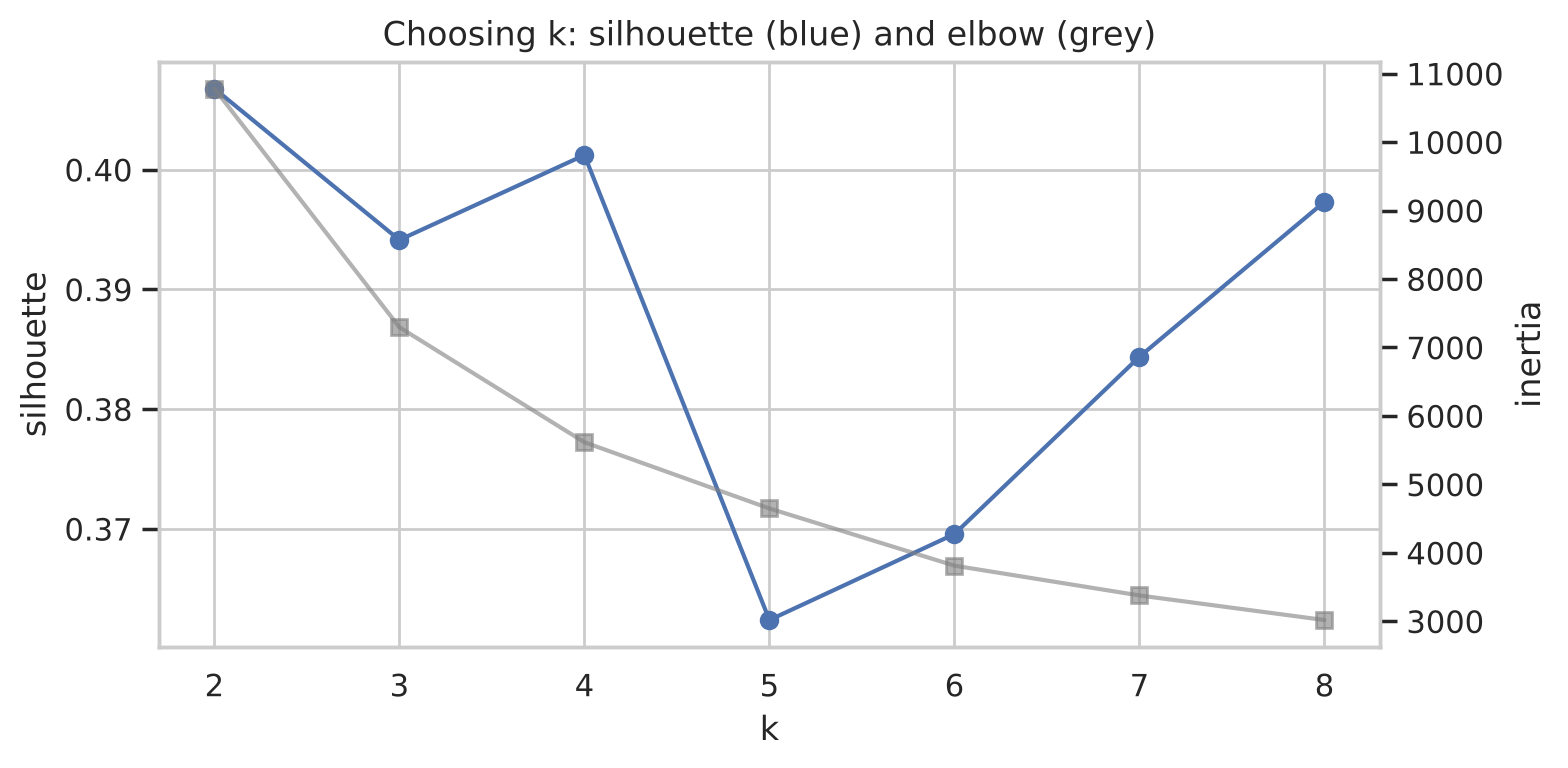

,k,silhouette,inertia
0,2,0.407,10782.454
1,3,0.394,7295.420
2,4,0.401,5615.076
3,5,0.362,4647.429
4,6,0.370,3812.392
5,7,0.384,3376.892
6,8,0.397,3017.768


In [14]:
sil = silhouette_by_k(df)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sil["k"], sil["silhouette"], marker="o"); ax1.set_xlabel("k"); ax1.set_ylabel("silhouette")
ax2 = ax1.twinx(); ax2.plot(sil["k"], sil["inertia"], marker="s", color="grey", alpha=0.6); ax2.set_ylabel("inertia")
ax2.grid(False)
ax1.set_title("Choosing k: silhouette (blue) and elbow (grey)")
plt.tight_layout(); plt.savefig(FIG / "kmeans_choose_k.png", dpi=150); plt.show()
sil.round(3)

k = 2 has the highest silhouette but only splits customers into "new" and "established". k = 4 is almost as
well separated (silhouette ≈ 0.40), sits at the elbow of the inertia curve, and gives more actionable groups,
so I use k = 4.

In [15]:
segments = fit_segments(df, k=4)
summary = describe_segments(df, segments)
summary

,customers,avg_tenure,avg_monthly_charges,avg_addon_services,churn_rate
segment,,,,,
3,2373,15.05,77.58,1.83,0.47
0,1521,10.16,29.58,0.30,0.24
1,2158,56.89,90.59,4.16,0.15
2,991,54.54,31.81,0.58,0.04


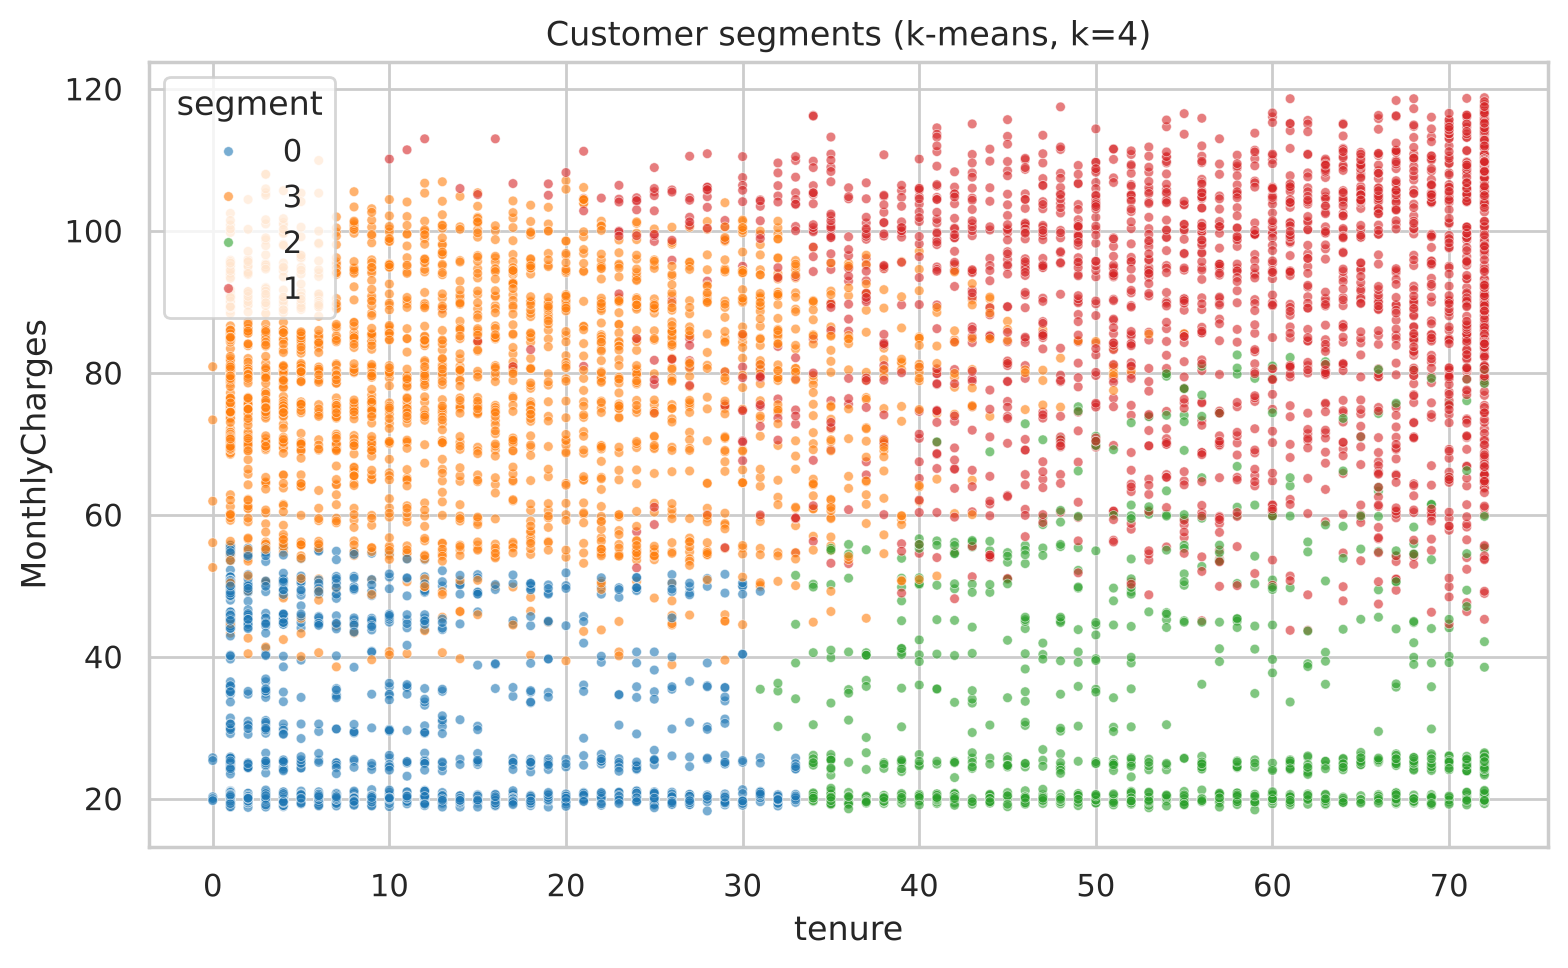

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=df["tenure"], y=df["MonthlyCharges"], hue=segments.astype(str), palette="tab10",
                s=12, alpha=0.6, ax=ax)
ax.set_title("Customer segments (k-means, k=4)"); ax.legend(title="segment")
plt.tight_layout(); plt.savefig(FIG / "segments.png", dpi=150); plt.show()

The segments differ sharply in churn even though churn was not used to build them: new customers on
expensive plans form the highest-risk group, while long-tenure customers with many add-on services rarely leave.
This suggests targeting onboarding and first-year offers at the high-charge new-customer segment.

## 9. Summary and limitations

* **SQL exploration:** churn is driven by contract type, early tenure, payment method and missing support services.
* **Modelling:** logistic regression matches random forest and gradient boosting (test ROC-AUC ≈ 0.84)
  with the smallest train/validation gap; the top 10% of scored customers churn at ~2.8× the base rate.
* **Overfitting:** a validation curve shows random forests underfit at depth 2 and overfit beyond depth ≈ 8.
* **Decision:** a profit-based threshold (≈0.3 under the stated assumptions) beats the default 0.5.
* **Segmentation:** k-means finds behaviour-based groups whose churn rates range from a few percent to roughly half.

**Limitations.** One snapshot dataset with no time dimension, so the model can't use behaviour changes
before churn; the campaign economics are assumptions; and all findings are correlational.